# Distribuciones categóricas y valores atípicos en seguros de automotores

¿Qué tipos de póliza y frecuencias de pago predominan en la cartera de 2024? ¿Entre qué edades se concentra la mitad central de los conductores y qué registros conviene revisar?

Se analiza una fila por cada póliza. El CSV tiene 47 columnas para de unas 168 mil pólizas con cobertura en 2024. Para este análisis se seleccionaron cuatro variables: tipo de cobertura, frecuencia de pago, edad del conductor y premio total. Se utiliza `insured_id`, el identificador del asegurado, como índice para localizar cada caso.

## 1. Carga y control de calidad

In [28]:
#Importación de librerias

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

# Cargar dataset en csv usando el identificador de póliza (insured_id) como índice
polizas_completas = pd.read_csv(Path("data") / "polizas.csv", index_col="insured_id")

# Seleccionar las variables de análisis
columnas_analisis = ["policy_type", "payment_frequency", "driver_age", "total_premium"]
polizas = polizas_completas[columnas_analisis].copy()

display(polizas.head())

,policy_type,payment_frequency,driver_age,total_premium
insured_id,,,,
2,COMP_E,A,45,584.632430
3,COMP_E,S,47,742.413461
4,CC,A,34,351.106210
5,TPG,A,41,244.810834
6,CC,A,31,239.611044


In [29]:
# Revisar tipo de datos y la cantidad de valores no nulos de cada columna.
polizas.info()

<class 'pandas.core.frame.DataFrame'>
Index: 168133 entries, 2 to 185678
Data columns (total 4 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   policy_type        168133 non-null  object 
 1   payment_frequency  168133 non-null  object 
 2   driver_age         168133 non-null  int64  
 3   total_premium      168133 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 6.4+ MB


In [30]:
#Revisar edad y premio, media y desviación estándar, mínimo y máximo, cuartiles y percentiles.
polizas.describe()

,driver_age,total_premium
count,168133.000000,168133.000000
mean,49.802484,303.553931
std,12.055782,227.718185
min,18.000000,0.000000
25%,40.000000,157.312835
50%,49.000000,266.377040
75%,59.000000,391.940498
max,90.000000,5104.205510


In [31]:
#Limpiar los códigos de cobertura y frecuencia de pago 

categoricas = ["policy_type", "payment_frequency"]
for columna in categoricas:
    polizas[columna] = polizas[columna].astype("string").str.strip().replace("", pd.NA)

# Tratamiento de faltantes o nulos en variable de edad.

edad = pd.to_numeric(polizas["driver_age"], errors="coerce")
polizas["driver_age"] = edad.where(edad.ge(0) & edad.mod(1).eq(0))
display(polizas.isna().sum().rename("Faltantes después de la limpieza"))
edades = polizas["driver_age"].dropna()

policy_type          0
payment_frequency    0
driver_age           0
total_premium        0
Name: Faltantes después de la limpieza, dtype: int64

## 2. Composición de la cartera

El primer gráfico muestra cómo se distribuyen las pólizas por tipo de cobertura y el segundo, por frecuencia de pago. En ambos gráficos, cada barra representa el porcentaje de la categoría sobre el total de pólizas del año.

| Código | Tipo de cobertura |
|---|---|
| TP | Responsabilidad civil básica frente a terceros. |
| TPG | Responsabilidad civil frente a terceros con cobertura de cristales. |
| CC | Responsabilidad civil frente a terceros con dos o más coberturas adicionales, como robo, incendio, pérdida total o cristales. |
| COMP_E | Todo riesgo con franquicia. |
| COMP_N | Todo riesgo sin franquicia. |

,Q_Polizas,Porcentaje
policy_type,,
CC,96452,57.37
COMP_E,45263,26.92
TPG,16543,9.84
COMP_N,6867,4.08
TP,3008,1.79


,Q_Polizas,Porcentaje
payment_frequency,,
A,140030,83.29
S,22369,13.3
Q,5734,3.41


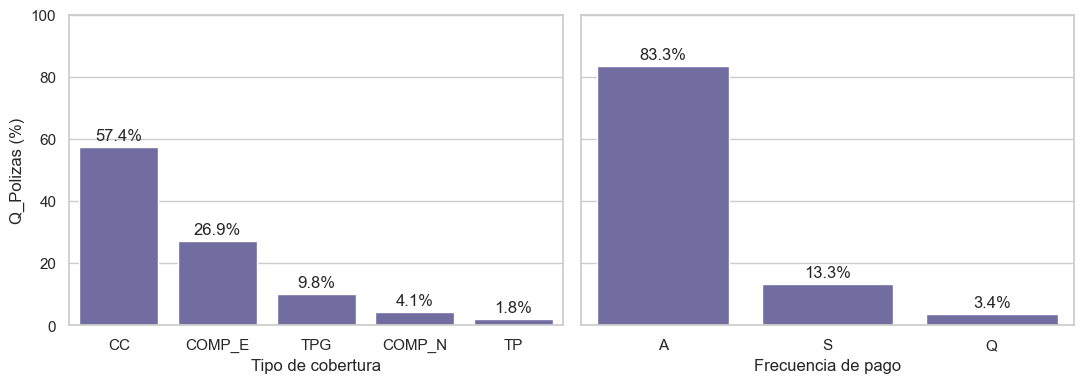

In [32]:
# Contar las pólizas por cobertura y frecuencia de pago 

etiquetas = {"policy_type": "Tipo de cobertura", "payment_frequency": "Frecuencia de pago"}
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for columna, eje in zip(categoricas, ejes):
    conteo = polizas[columna].fillna("Sin dato").value_counts()
    tabla = conteo.rename("Q_Polizas").to_frame()
    tabla["Porcentaje"] = 100 * conteo / len(polizas)
    display(tabla.round(2))
    sns.barplot(x=tabla.index, y=tabla["Porcentaje"], ax=eje, color="#6b65a8")
    eje.bar_label(eje.containers[0], fmt="%.1f%%", padding=3)
    eje.set(xlabel=etiquetas[columna], ylabel="Q_Polizas (%)", ylim=(0, 100))
fig.tight_layout()
plt.show()

El tipo de póliza más frecuente es CC - Responsabilidad civil frente a terceros con dos o más(57,4 %). La concentración es mayor en la frecuencia de pago es Anual, reúne el 83,3 % de las pólizas.

## 3. Centro, dispersión y forma de la edad

In [33]:
## Calcular los cuartiles y el IQR para describir la dispersión del 50 % central de las edades

q1, q3 = edades.quantile([0.25, 0.75])
iqr = q3 - q1
resumen = pd.Series({
    "Media": edades.mean(),
    "Mediana": edades.median(),
    "Moda": edades.mode().iloc[0],
    "Desvío estándar muestral": edades.std(),
    "Mínimo": edades.min(),
    "Q1": q1,
    "Q3": q3,
    "Máximo": edades.max(),
    "IQR": iqr,
    "Asimetría": edades.skew(),
    "Exceso de curtosis (Fisher)": edades.kurt(),
})
display(resumen.round(3).rename("Edad del conductor"))

Media                          49.802
Mediana                        49.000
Moda                           41.000
Desvío estándar muestral       12.056
Mínimo                         18.000
Q1                             40.000
Q3                             59.000
Máximo                         90.000
IQR                            19.000
Asimetría                       0.227
Exceso de curtosis (Fisher)    -0.842
Name: Edad del conductor, dtype: float64

La mitad central se ubica entre 40 y 59 años. La media (49,80 años) supera levemente a la mediana (49). La asimetría positiva (0,227) indica una cola algo más larga hacia las edades altas. El exceso de curtosis (−0,842) se compara con el valor 0 de una normal e indica colas globalmente más livianas. Aun así, puede haber observaciones individuales fuera de los límites del IQR.

## 4. Boxplot y violin plot
Ambos gráficos usan la misma escala. En el boxplot, los bigotes llegan hasta la edad observada más extrema dentro de cada límite. En el violín, el ancho representa la densidad estimada y las líneas interiores indican los cuartiles.

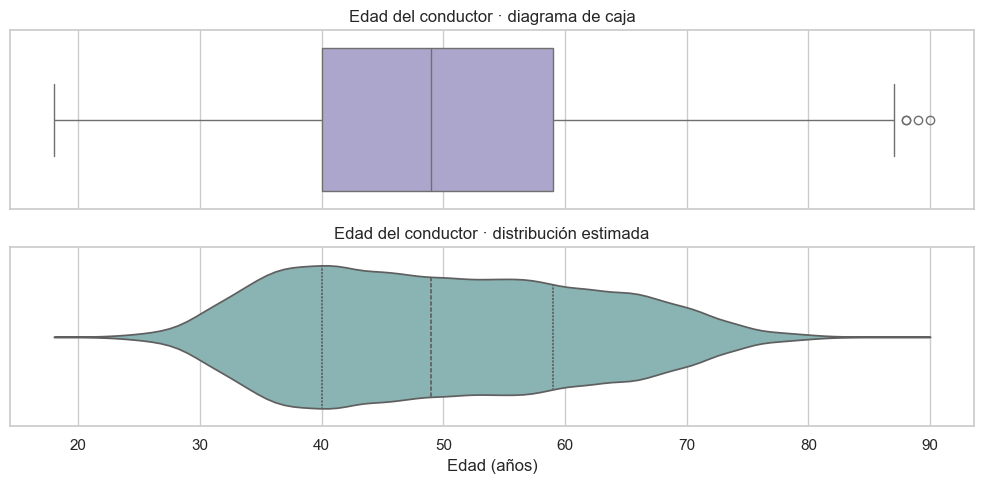

In [34]:
## Comparar en la misma escala los extremos de la edad (boxplot) y dónde se concentran los registros (violín).

fig, (caja, violin) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
sns.boxplot(x=edades, whis=1.5, color="#a7a0d2", ax=caja)
sns.violinplot(x=edades, inner="quart", cut=0, color="#83bbba", ax=violin)
caja.set(title="Edad del conductor · diagrama de caja", xlabel="")
violin.set(title="Edad del conductor · distribución estimada", xlabel="Edad (años)")
fig.tight_layout()
plt.show()

El violín se ensancha en las edades intermedias y se afina hacia las mayores. En el boxplot aparecen puntos a la derecha del bigote superior. Dos observaciones de 88 años se superponen, por lo que el conteo exacto se obtiene en la tabla siguiente.

## 5. Identificación y segmentación por IQR

In [35]:
# Aplicar regla de 1,5 veces el IQR para clasificar las edades y listar los registros atípicos

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
edad = polizas["driver_age"]
segmento = pd.Series("Dentro de límites", index=polizas.index)
segmento.loc[edad.isna()] = "Sin edad válida"
segmento.loc[edad < limite_inferior] = "Atípico inferior"
segmento.loc[edad > limite_superior] = "Atípico superior"
polizas["segmento_iqr"] = segmento

print(f"Límites IQR: {limite_inferior:g} a {limite_superior:g} años")
orden = ["Atípico inferior", "Dentro de límites", "Atípico superior", "Sin edad válida"]
display(segmento.value_counts().reindex(orden, fill_value=0).rename("Q_Polizas").to_frame())
atipicos = polizas.loc[segmento.isin(["Atípico inferior", "Atípico superior"])]
display(atipicos.sort_values("driver_age", ascending=False))

Límites IQR: 11.5 a 87.5 años


,Q_Polizas
Atípico inferior,0
Dentro de límites,168129
Atípico superior,4
Sin edad válida,0


,policy_type,payment_frequency,driver_age,total_premium,segmento_iqr
insured_id,,,,,
26215,TPG,A,90,191.136444,Atípico superior
7441,TPG,A,89,248.002997,Atípico superior
3562,CC,A,88,381.438426,Atípico superior
17504,CC,A,88,318.516683,Atípico superior


Asimetría del premio: 2.456
Exceso de curtosis del premio: 14.985
Límites IQR: -194.63 a 743.88
Q_Polizas con premio atípico: 7,075


,policy_type,payment_frequency,driver_age,total_premium
insured_id,,,,
33666,COMP_N,A,33,5104.205510
14721,COMP_N,A,47,4689.022184
116275,COMP_N,A,40,4321.101371
70095,COMP_N,A,41,3806.088488
76162,COMP_E,A,49,3643.125097
34079,COMP_N,A,67,3530.010018
81517,COMP_E,A,48,3506.471480
73218,COMP_N,A,56,3196.531602
21044,COMP_N,A,44,3184.576206


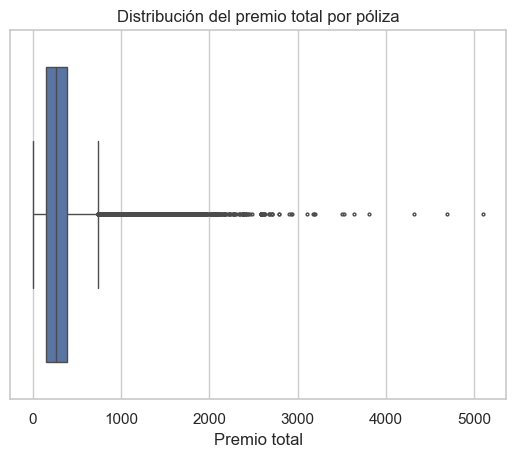

Asimetría del premio: 2.456
Exceso de curtosis del premio: 14.985


In [36]:
# Calcular límites propios para el premio total e identificar las pólizas con importes atípicos

premio = polizas["total_premium"]

# Medir la asimetría y el exceso de curtosis del premio total.
print(f"Asimetría del premio: {premio.skew():.3f}")
print(f"Exceso de curtosis del premio: {premio.kurt():.3f}")

q1_premio, q3_premio = premio.quantile([0.25, 0.75])
iqr_premio = q3_premio - q1_premio

limite_inferior_premio = q1_premio - 1.5 * iqr_premio
limite_superior_premio = q3_premio + 1.5 * iqr_premio

# Seleccionar los casos fuera de los límites propios del premio
fuera_de_limites = (premio < limite_inferior_premio) | (premio > limite_superior_premio)
atipicos_premio = polizas.loc[fuera_de_limites, columnas_analisis]

print(f"Límites IQR: {limite_inferior_premio:.2f} a {limite_superior_premio:.2f}")
print(f"Q_Polizas con premio atípico: {len(atipicos_premio):,}")
display(atipicos_premio.nlargest(10, "total_premium"))

sns.boxplot(x=premio, whis=1.5, fliersize=2)
plt.title("Distribución del premio total por póliza")
plt.xlabel("Premio total")
plt.show()
print(f"Asimetría del premio: {premio.skew():.3f}")
print(f"Exceso de curtosis del premio: {premio.kurt():.3f}")

## Conclusión y decisión
El intervalo de referencia va de 11,5 a 87,5 años. Hay cuatro pólizas por encima del límite superior (88, 88, 89 y 90 años) y ninguna por debajo del inferior. Los cuatro casos representan aproximadamente el 0,0024 % de las pólizas de esta cartera.

Conservaría los cuatro registros ya que son edades posibles y concuerdan con el extremo derecho que muestra el boxplot. Para validar cada caso, contrastaría la edad con la fecha de nacimiento. Corregiría únicamente errores confirmados. Para describir al conductor típico usaría la mediana y el IQR, manteniendo la edad en años para facilitar su interpretación.

La mediana del premio total es 266,38. La distribución presenta asimetría positiva (2,456) y un exceso de curtosis de 14,985. En el boxplot se observa una cola hacia los importes altos. El límite superior del IQR es 743,88 y lo superan 7.075 pólizas, equivalentes al 4,21 % de la cartera. Conservaría estos registros y revisaría los importes dentro de cada tipo de póliza y frecuencia de pago antes de decidir si corresponde corregir alguno.